In [32]:
import yfinance as yf
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [14]:
#S&P 500 and VIX data
tickers = ["^GSPC", "^VIX"]
market_data = yf.download(tickers, start="2020-01-01", end="2026-10-20")

print(market_data.shape)
print(market_data.isnull().sum())
#print(market_data.head())

[*********************100%***********************]  2 of 2 completed

(1710, 10)
Price   Ticker
Close   ^GSPC     2
        ^VIX      0
High    ^GSPC     2
        ^VIX      0
Low     ^GSPC     2
        ^VIX      0
Open    ^GSPC     2
        ^VIX      0
Volume  ^GSPC     2
        ^VIX      0
dtype: int64


In [15]:
market_data.to_csv("../data/raw/raw_market.csv")

In [16]:
import sys
from pathlib import Path 
sys.path.append(str(Path("../src").resolve()))

from my_functions import clean_columns, vix_segments, missing_values
import pandas as pd

In [ ]:
missing_values(market_data).head()
print(missing_values(market_data).isnull().sum())

In [20]:
processed_df = (
    market_data.copy()
    .pipe(clean_columns)
    .pipe(missing_values)
    .pipe(vix_segments)
)

processed_df.to_csv("../data/processed/market_processed.csv")

print(processed_df.isnull().sum())
processed_df.head()

Close_^GSPC     0
Close_^VIX      0
High_^GSPC      0
High_^VIX       0
Low_^GSPC       0
Low_^VIX        0
Open_^GSPC      0
Open_^VIX       0
Volume_^GSPC    0
Volume_^VIX     0
VIX_Segments    0
dtype: int64


,Close_^GSPC,Close_^VIX,High_^GSPC,High_^VIX,Low_^GSPC,Low_^VIX,Open_^GSPC,Open_^VIX,Volume_^GSPC,Volume_^VIX,VIX_Segments
Date,,,,,,,,,,,
2020-01-02,3257.850098,12.47,3258.139893,13.720000,3235.530029,12.42,3244.669922,13.46,3.459930e+09,0,Low (0-15)
2020-01-03,3234.850098,14.02,3246.149902,16.200001,3222.340088,13.13,3226.360107,15.01,3.484700e+09,0,Low (0-15)
2020-01-06,3246.280029,13.85,3246.840088,16.389999,3214.639893,13.54,3217.550049,15.45,3.702460e+09,0,Low (0-15)
2020-01-07,3237.179932,13.79,3244.909912,14.460000,3232.429932,13.39,3241.860107,13.84,3.435910e+09,0,Low (0-15)
2020-01-08,3253.050049,13.45,3267.070068,15.240000,3236.669922,12.83,3238.590088,15.16,3.726840e+09,0,Low (0-15)


In [21]:
volume_summary = processed_df.groupby('VIX_Segments')['Volume_^GSPC'].agg(['count', 'mean', 'median'])
print("S&P 500 Volume Summary by VIX Segments")
print(volume_summary)

S&P 500 Volume Summary by VIX Regime
                 count          mean        median
VIX_Segments                                      
Elevated(20-25)    358  4.598518e+09  4.462525e+09
High (25-30)       197  4.942747e+09  4.714880e+09
Low (0-15)         299  4.014841e+09  3.845600e+09
Normal (15-20)     707  4.514294e+09  4.355860e+09
X-Treme! (30+)     149  5.828453e+09  5.436230e+09


In [31]:
processed_df['SP500_Return'] = processed_df['Close_^GSPC'].pct_change()
processed_df['VIX_Change'] = processed_df['Close_^VIX'].diff()
correlation = processed_df[['SP500_Return', 'VIX_Change']].corr().loc['SP500_Return', 'VIX_Change']
print("Return vs. Volatility Correlation")
print(correlation.round(3))

Return vs. Volatility Correlation
-0.782


In [37]:
processed_df['SP500_Return'] = processed_df['Close_^GSPC'].pct_change() * 100
processed_df['Negative_Day'] = processed_df['SP500_Return'] < 0

order = ['Low (0-15)', 'Normal (15-20)', 'Elevated(20-25)', 'High (25-30)', 'X-Treme! (30+)']

segment_summary = (
    processed_df.dropna(subset=['SP500_Return'])
    .groupby('VIX_Segments')
    .agg(
        Total_Days=('SP500_Return', 'count'),
        Negative_Days=('Negative_Day', 'sum'),
        Percent_Negative_Days=('Negative_Day', lambda x: x.mean() * 100),
        Mean_Return=('SP500_Return', 'mean'),
        Median_Return=('SP500_Return', 'median'),
        Std_Dev_Return=('SP500_Return', 'std')
    )
    .reindex(order)
)

print("S&P 500 Daily Return Stats by VIX Segment")
print(segment_summary.round(3))

S&P 500 Daily Return Stats by VIX Segment
                 Total_Days  Negative_Days  Percent_Negative_Days  \
VIX_Segments                                                        
Low (0-15)              298            107                 35.906   
Normal (15-20)          707            300                 42.433   
Elevated(20-25)         358            182                 50.838   
High (25-30)            197            104                 52.792   
X-Treme! (30+)          149             92                 61.745   

                 Mean_Return  Median_Return  Std_Dev_Return  
VIX_Segments                                                 
Low (0-15)             0.212          0.169           0.571  
Normal (15-20)         0.146          0.126           0.732  
Elevated(20-25)        0.025         -0.029           1.097  
High (25-30)          -0.038         -0.211           1.447  
X-Treme! (30+)        -0.457         -0.565           3.054  


In [62]:

fig_dir = Path("../figures")
fig_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
order = ['Low (0-15)', 'Normal (15-20)', 'Elevated(20-25)', 'High (25-30)', 'X-Treme! (30+)']
palette = ['#2b5c8f', '#3690c0', '#f6c85f', '#e67f33', '#d9381e']

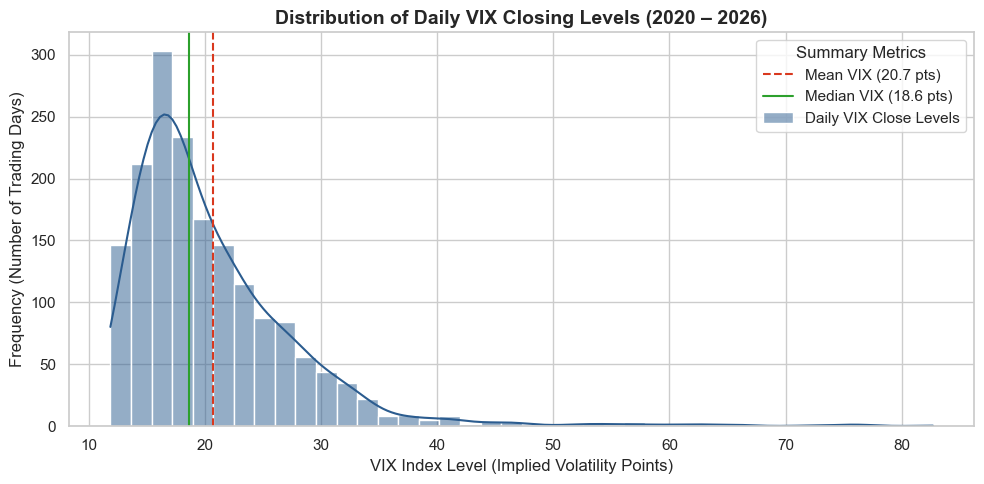

In [61]:
plt.figure(figsize=(10, 5))
sns.histplot(processed_df['Close_^VIX'], bins=40, kde=True, color='#2b5c8f', label='Daily VIX Close Levels')
plt.axvline(processed_df['Close_^VIX'].mean(), color='#d9381e', linestyle='--', linewidth=1.5, label=f"Mean VIX ({processed_df['Close_^VIX'].mean():.1f} pts)")
plt.axvline(processed_df['Close_^VIX'].median(), color='#2ca02c', linestyle='-', linewidth=1.5, label=f"Median VIX ({processed_df['Close_^VIX'].median():.1f} pts)")
plt.title("Distribution of Daily VIX Closing Levels (2020 – 2026)", fontsize=14, fontweight='bold')
plt.xlabel("VIX Index Level (Implied Volatility Points)", fontsize=12)
plt.ylabel("Frequency (Number of Trading Days)", fontsize=12)
plt.legend(title="Summary Metrics")
plt.tight_layout()
plt.savefig(fig_dir / "1_vix_distribution.png", dpi=300)
plt.show()

Looks like daily VIX volume closing levels exhibit a strong right-skewed distribution. The majority of trading days between tend to stay between 15 and 25 points with an extended tail above 30 during market turmoil.


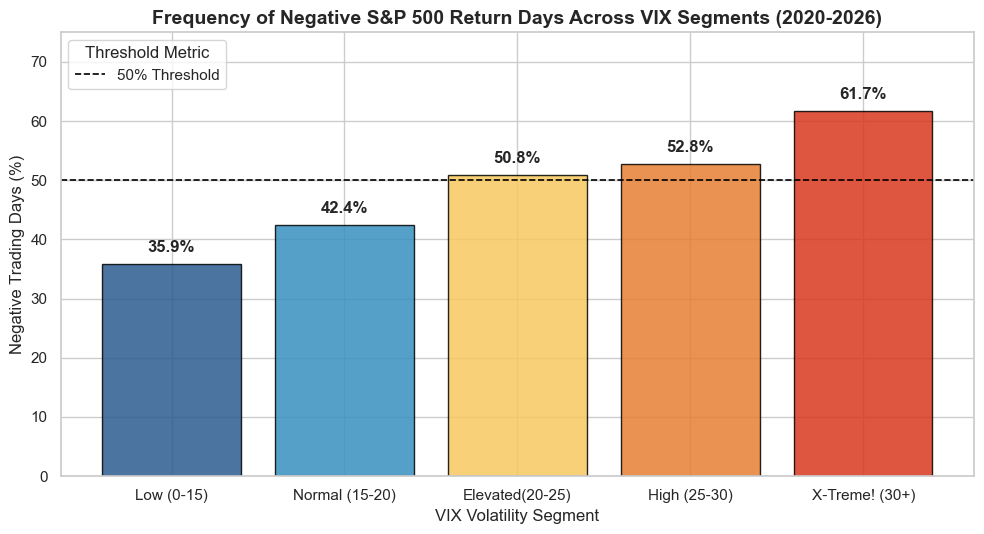

In [60]:
fig, ax1 = plt.subplots(figsize=(10, 5.5))
bars = ax1.bar(
    segment_summary.index,
    segment_summary['Percent_Negative_Days'],
    color=palette,
     edgecolor='black',
    alpha=0.85,
  
)

ax1.axhline(50, color='black', linestyle='--', linewidth=1.2, label='50% Threshold')
ax1.set_title("Frequency of Negative S&P 500 Return Days Across VIX Segments (2020-2026)", fontsize=14, fontweight='bold')
ax1.set_xlabel("VIX Volatility Segment", fontsize=12)
ax1.set_ylabel("Negative Trading Days (%)", fontsize=12)
ax1.set_ylim(0, 75)

for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 1.5, f"{height:.1f}%", ha='center', va='bottom', fontweight='bold')

ax1.legend(loc='upper left', title="Threshold Metric")
plt.tight_layout()
plt.savefig(fig_dir / "2_segment_comparison.png", dpi=300)
plt.show()








The percentage of negative S&P 500 trading days increases across volatility brackets, rising from 35.9% in the Low regime (0–15) to 61.7% in the Extreme regime (30+).

Cool!

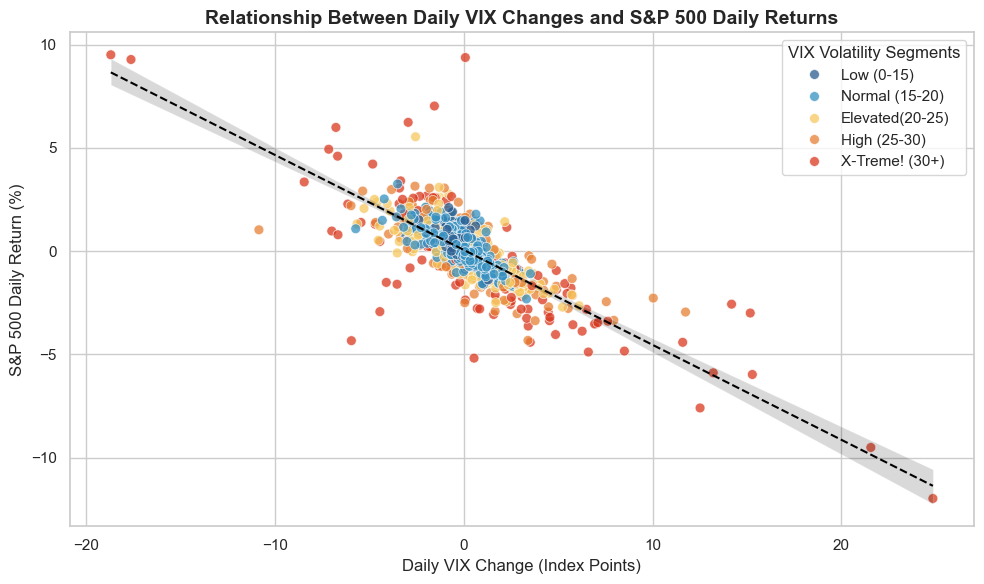

In [53]:
plt.figure(figsize=(10, 6))
clean_plot_df = processed_df.dropna(subset=['SP500_Return', 'VIX_Change'])

sns.scatterplot(
    data=clean_plot_df,
    x='VIX_Change',
    y='SP500_Return',
    hue='VIX_Segments',
    hue_order=order,
    palette=palette,
    alpha=0.75,
    s=50
)
sns.regplot(
    data=clean_plot_df,
    x='VIX_Change',
    y='SP500_Return',
    scatter=False,
    color='black',
    line_kws={'linestyle': '--', 'linewidth': 1.5, 'label': f'OLS Fit (r = {correlation:.3f})'}
)
plt.title("Relationship Between Daily VIX Changes and S&P 500 Daily Returns", fontsize=14, fontweight='bold')
plt.xlabel("Daily VIX Change (Index Points)", fontsize=12)
plt.ylabel("S&P 500 Daily Return (%)", fontsize=12)
plt.legend(title="VIX Volatility Segments", loc='upper right')
plt.tight_layout()
plt.savefig(fig_dir / "3_return_vs_vix.png", dpi=300)
plt.show()


VIX daily point changes and S&P 500 percentage returns display a medium strength negative correlation (r = -0.782), with the largest downward equity swings occurring during X-Treme volatility spikes.